## West Jutland Vessel Characteristics and Route Choice (Flag 12)

### Dataset Overview
A constructed Danish AIS-style case with 100 complete waterborne trajectories in the North Sea west of Jutland. It contains a bidirectional offshore route and lower-volume connectors to Esbjerg, Hvide Sande, and Thyborøn, plus static vessel characteristics and route references.

The notebook exposes a primary table and a supporting table (`vessels.csv`).

Goal: Investigate how vessel characteristics are associated with route choice in the sea area.

Role: Maritime traffic analyst


Category: vessel characteristics and offshore-versus-local route choice

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "vessels.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How is vessel traffic organized between the offshore corridor and local harbour routes?

#### Analysis action

Classify trajectories against the supplied route references and compare route-class counts.

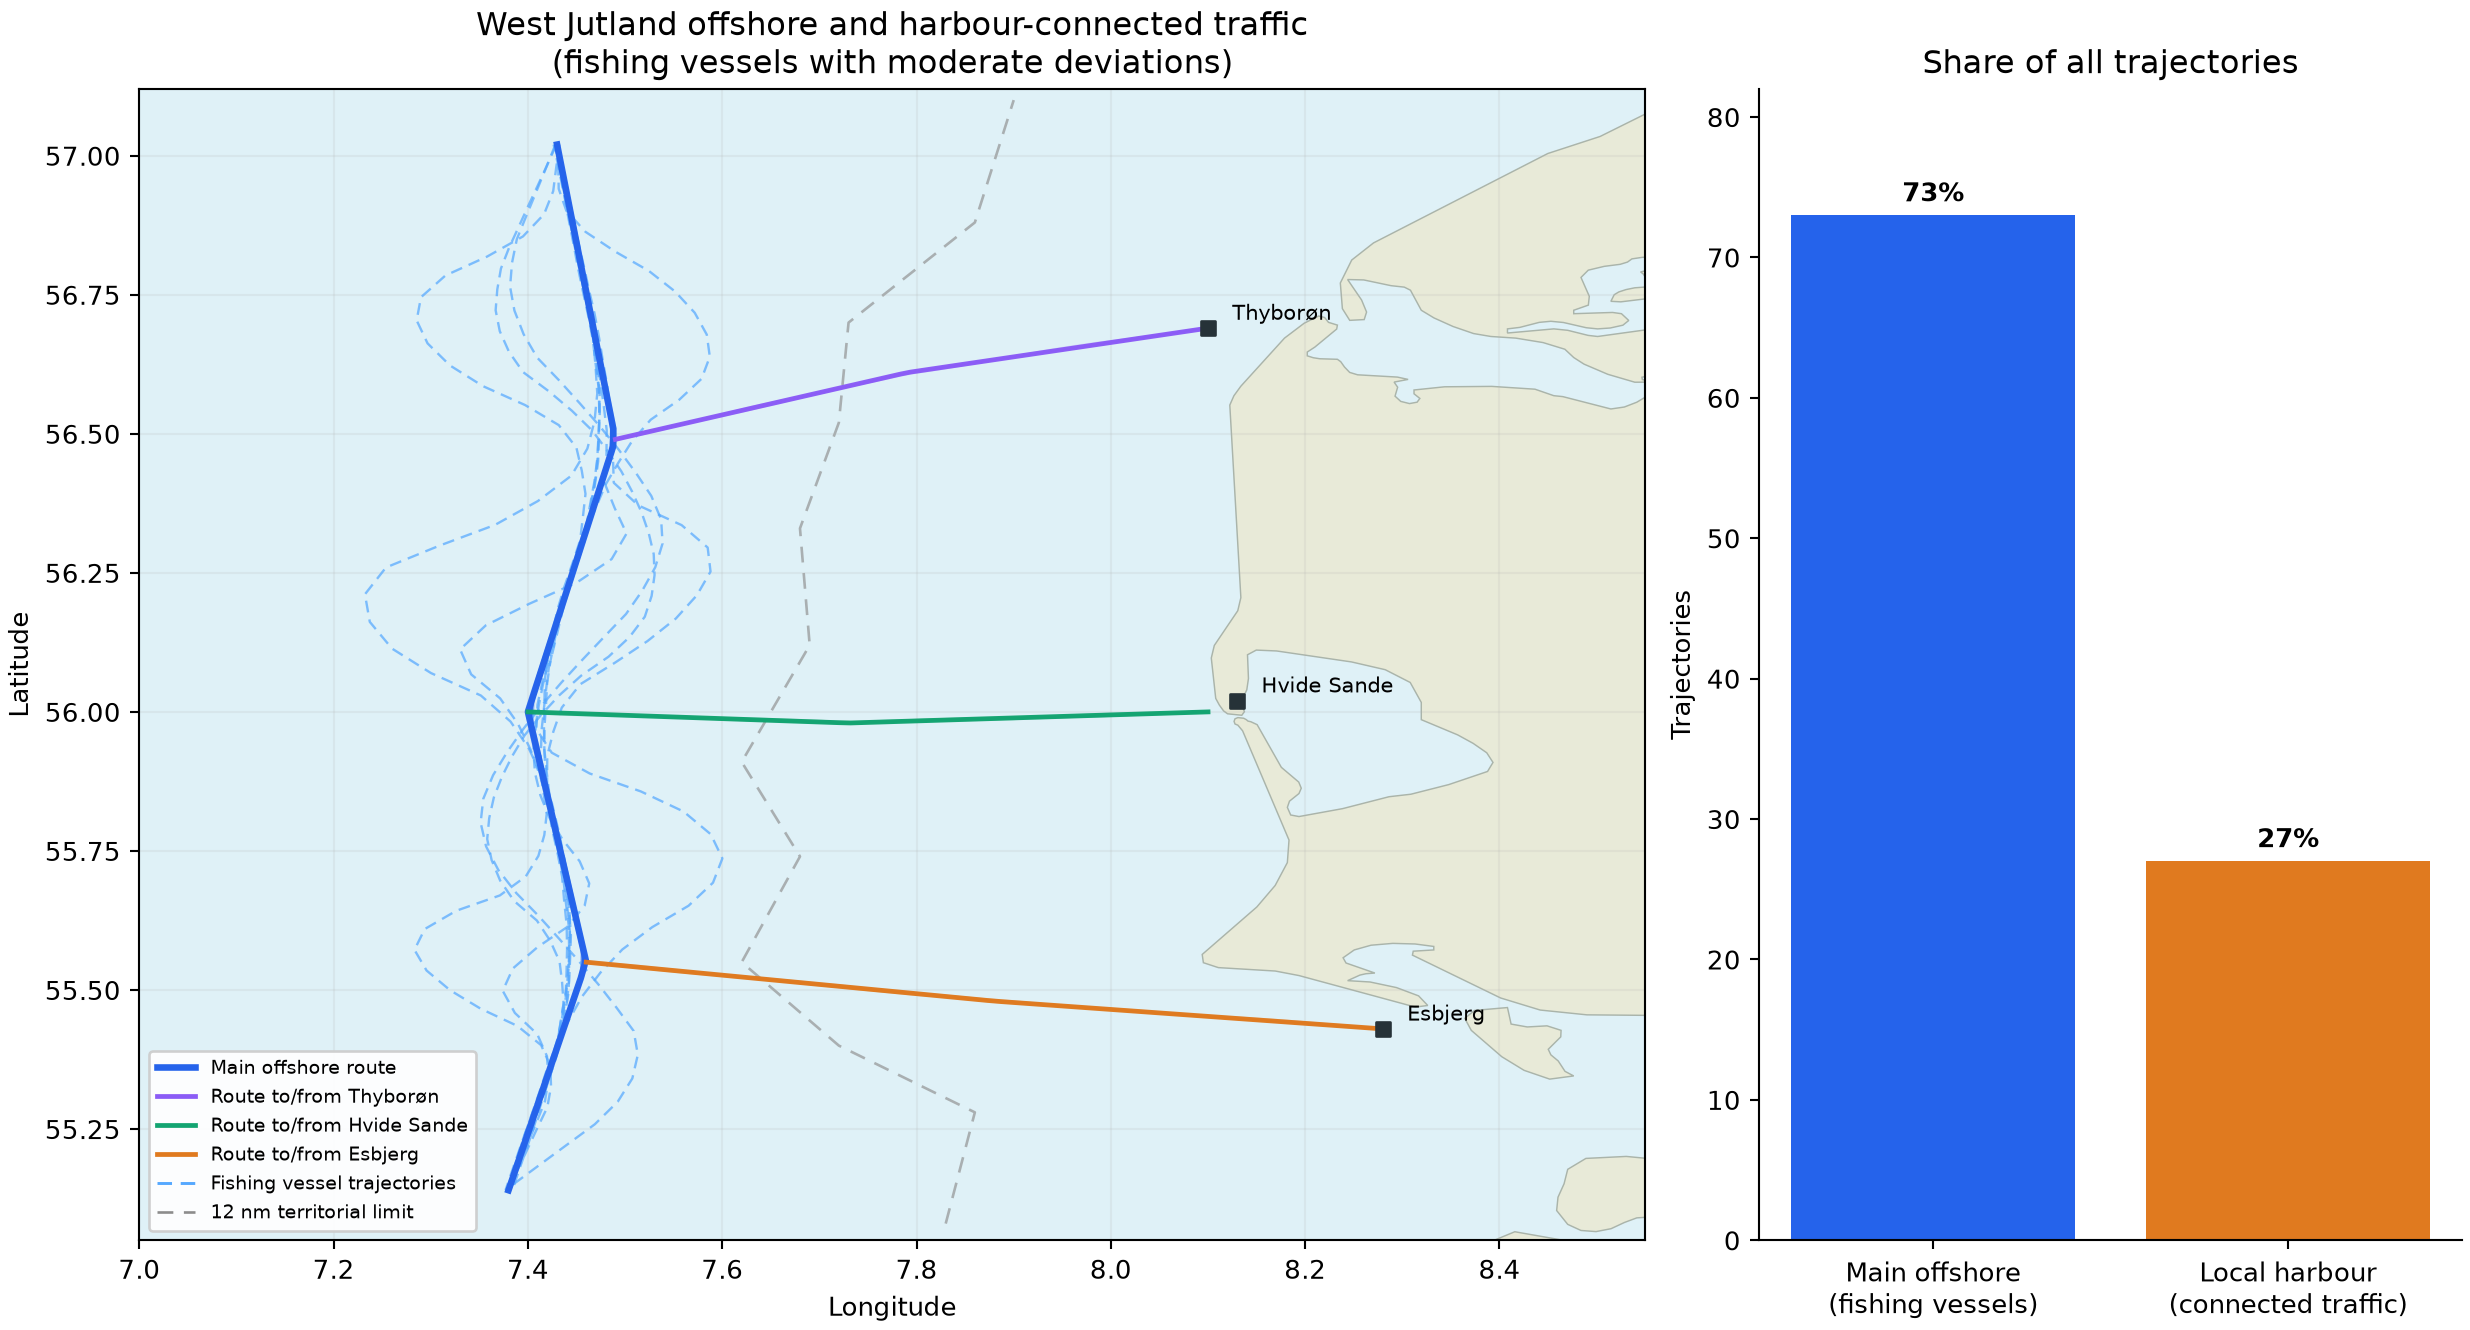

In [ ]:
import pandas as pd
from pathlib import Path
points=pd.read_csv(dataset_path); refs=pd.read_csv(Path('route_references.csv'))
print(points.groupby('trajectory_id').size().describe()); print(refs.groupby(['route_class','route_name']).size())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/route_traffic_structure.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "route_traffic_structure",
  "insight": "Traffic is organized around one heavily used offshore transit route and several lower-volume routes connecting local harbours and coastal waters.",
  "insight_value": {
    "main_offshore_trajectories": 73,
    "local_harbour_trajectories": 27,
    "main_route_share": 0.73
  },
  "plot": {
    "plot_type": "map_and_count_bar",
    "title": "West Jutland Route Traffic Structure",
    "file": "visualizations/route_traffic_structure.png",
    "description": "Complete waterborne trajectories and counts distinguish the main offshore route from three harbour connectors."
  },
  "question": "How is vessel traffic organized between the offshore corridor and local harbour routes?",
  "actionable_insight": "Classify trajectories against the supplied route references and compare route-class counts.",
  "code": "import pandas as pd\nfrom pathlib import Path\npoints=pd.read_csv(dataset_path); refs=pd.read_csv(Path('route_references.csv'))\nprint(points.groupby('trajectory_id').size().describe()); print(refs.groupby(['route_class','route_name']).size())",
  "insight_type": "overall_pattern",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "route_reference",
    "harbour_location",
    "vessel_id",
    "ship_type"
  ]
}

### **Question 2**: How are vessel type and dimensions associated with offshore versus harbour-connected route use?

#### Analysis action

Link vessel attributes by vessel_id after assigning each trajectory to its nearest route reference.

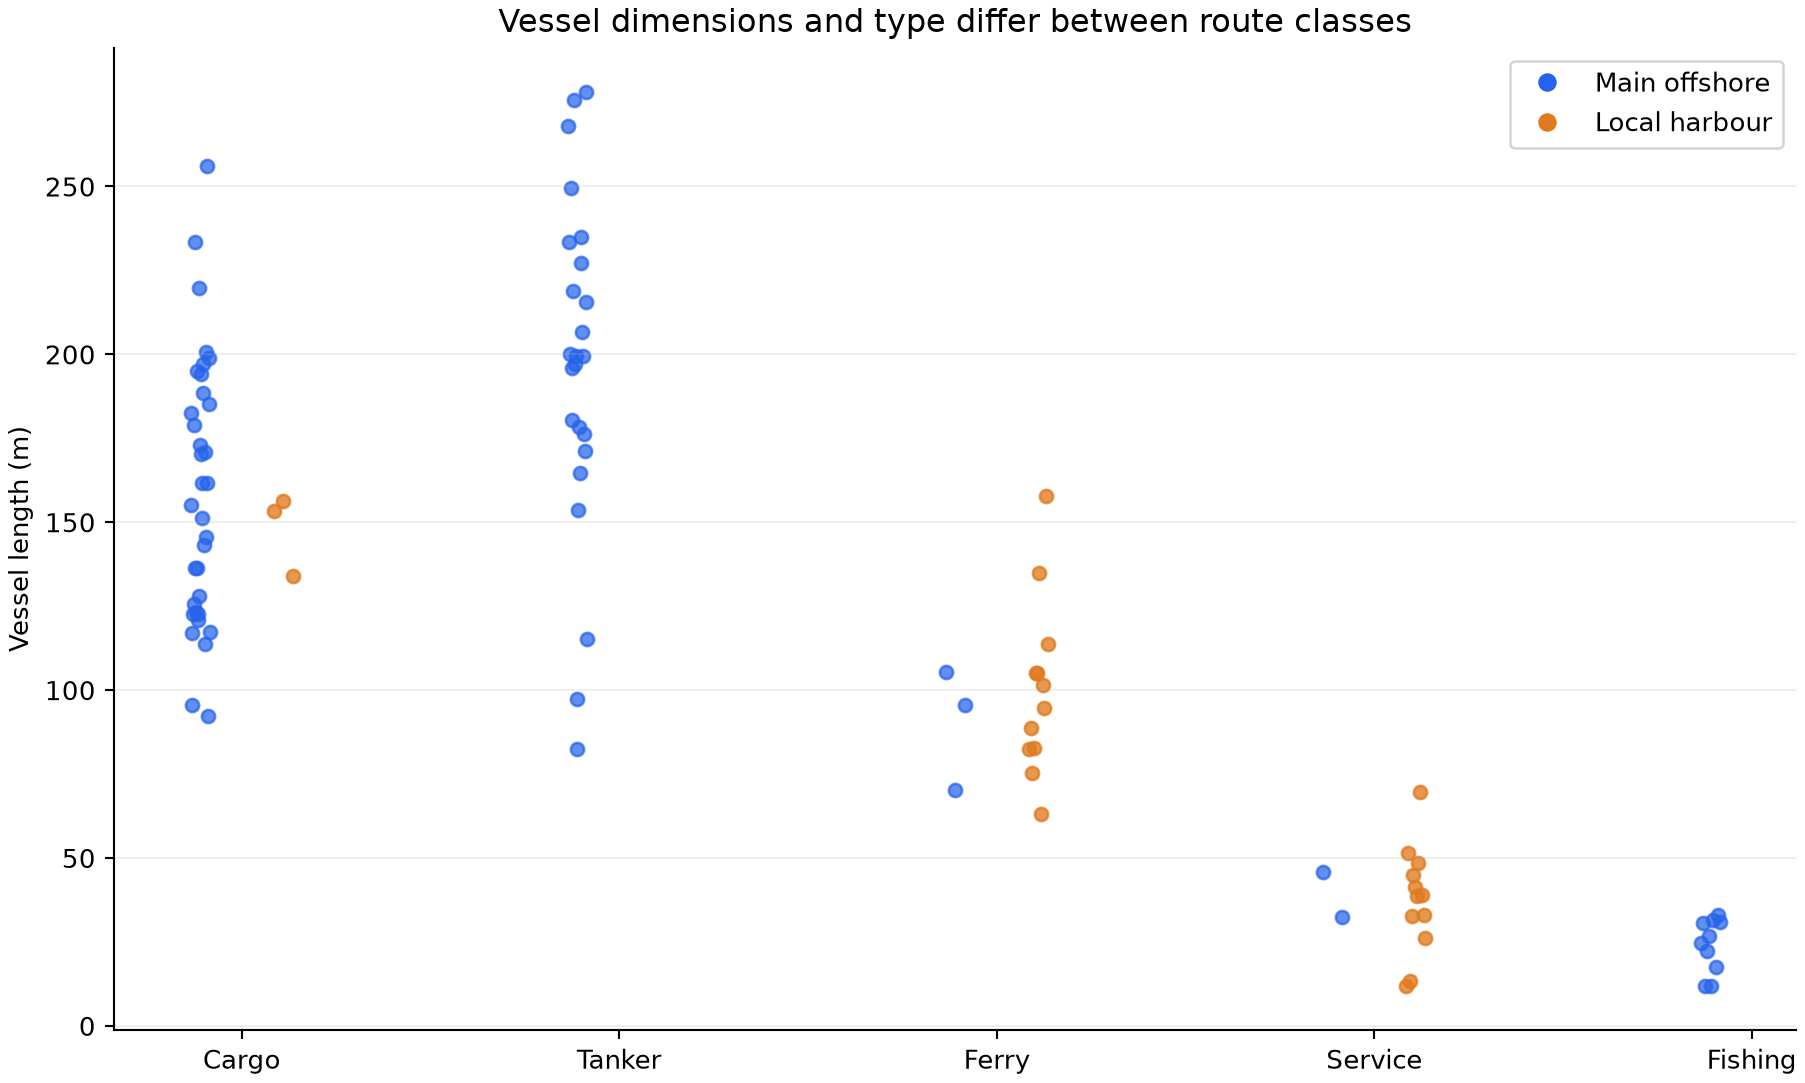

In [ ]:
import pandas as pd
ships=pd.read_csv(user_dataset_path)
print(ships.groupby('ship_type').length_m.describe())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/vessel_characteristics_by_route.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "vessel_characteristics_route_association",
  "insight": "Larger cargo and tanker vessels are concentrated on the main offshore routes, while smaller vessels are more common on routes connected to local harbours.",
  "insight_value": {
    "main_offshore_type_counts": {
      "Tanker": 24,
      "Cargo": 34,
      "Fishing": 10,
      "Ferry": 3,
      "Service": 2
    },
    "local_harbour_type_counts": {
      "Ferry": 12,
      "Service": 12,
      "Cargo": 3
    },
    "median_length_m": {
      "main_offshore": 161.6,
      "local_harbour": 75.2
    }
  },
  "plot": {
    "plot_type": "grouped_jittered_distribution",
    "title": "Vessel Characteristics by Route Class",
    "file": "visualizations/vessel_characteristics_by_route.png",
    "description": "Vessel length is shown by ship type and inferred route class without using categorical size labels."
  },
  "question": "How are vessel type and dimensions associated with offshore versus harbour-connected route use?",
  "actionable_insight": "Link vessel attributes by vessel_id after assigning each trajectory to its nearest route reference.",
  "code": "import pandas as pd\nships=pd.read_csv(user_dataset_path)\nprint(ships.groupby('ship_type').length_m.describe())",
  "insight_type": "overall_pattern",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "route_reference",
    "harbour_location",
    "ship_type",
    "vessel_length",
    "vessel_id"
  ]
}

### **Question 3**: On the main offshore route, does route regularity differ between cargo/tanker traffic and fishing vessels?

#### Analysis action

Restrict trajectories to the main offshore route, then measure mean distance from the nearest supplied route reference and compare vessel types.

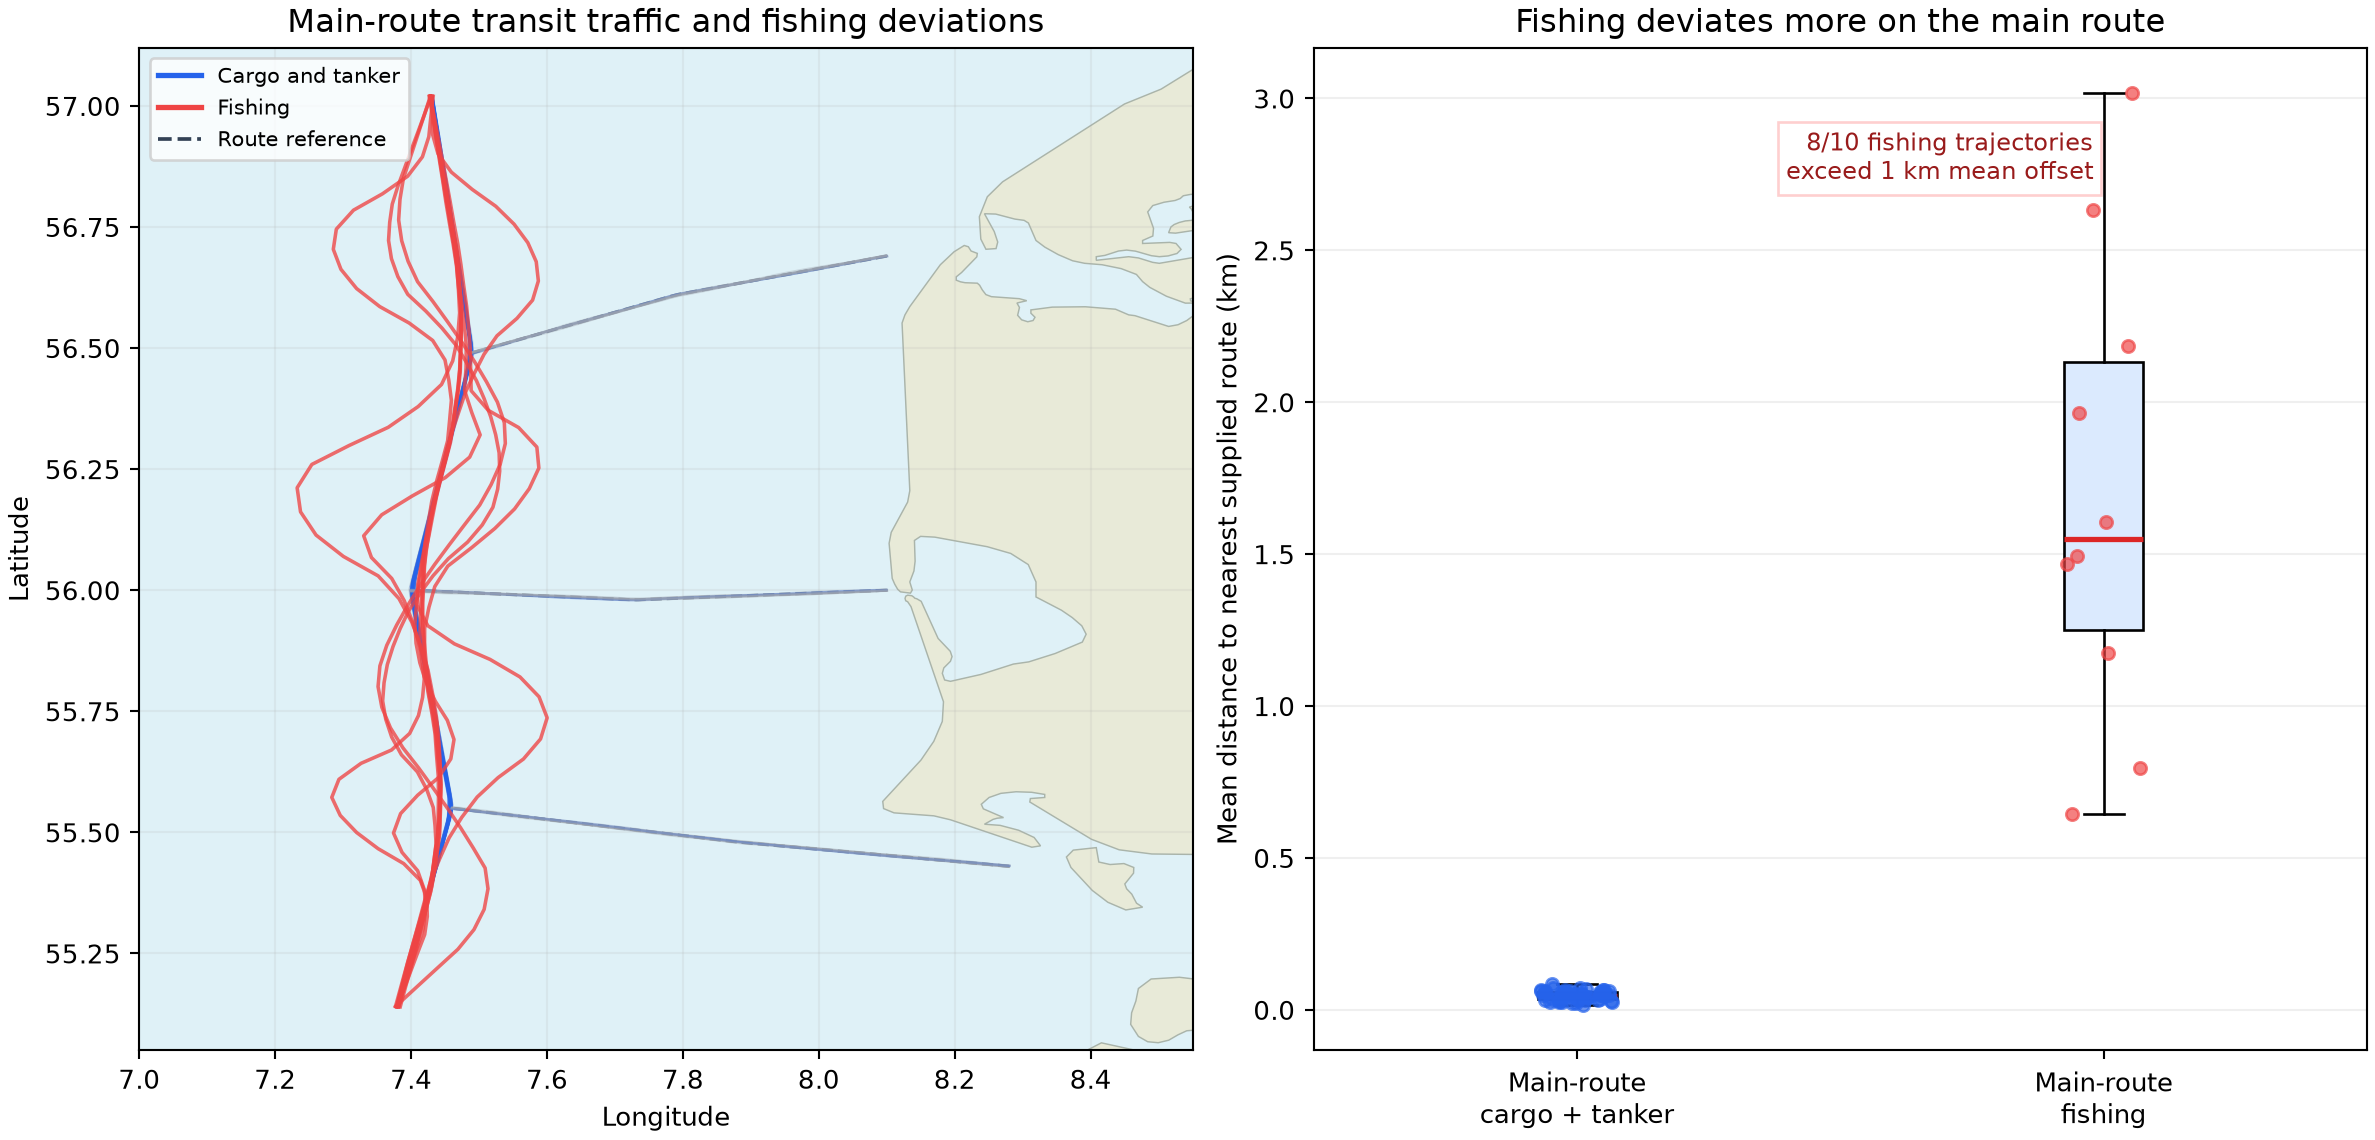

In [ ]:
import pandas as pd
from pathlib import Path
points=pd.read_csv(dataset_path); ships=pd.read_csv(user_dataset_path); refs=pd.read_csv(Path('route_references.csv'))
print(ships[['vessel_id','ship_type','length_m']].head())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/route_regularity_by_type.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "main_offshore_route_regularity",
  "insight": "On the main offshore route, cargo and tanker traffic follows the route closely, while fishing vessels show more spatially dispersed movement with moderate deviations from the route.",
  "insight_value": {
    "median_mean_route_offset_km": {
      "cargo_tanker": 0.047,
      "main_offshore_fishing": 1.55
    },
    "comparison_scope": "main offshore route only"
  },
  "plot": {
    "plot_type": "map_and_boxplot",
    "title": "Main-route Regularity by Vessel Type",
    "file": "visualizations/route_regularity_by_type.png",
    "description": "The map and offset distributions compare cargo/tanker and fishing trajectories assigned to the main offshore route; harbour-route fishing vessels are excluded by construction."
  },
  "question": "On the main offshore route, does route regularity differ between cargo/tanker traffic and fishing vessels?",
  "actionable_insight": "Restrict trajectories to the main offshore route, then measure mean distance from the nearest supplied route reference and compare vessel types.",
  "code": "import pandas as pd\nfrom pathlib import Path\npoints=pd.read_csv(dataset_path); ships=pd.read_csv(user_dataset_path); refs=pd.read_csv(Path('route_references.csv'))\nprint(ships[['vessel_id','ship_type','length_m']].head())",
  "insight_type": "group_comparison",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "route_reference",
    "ship_type",
    "vessel_id"
  ]
}

### Summary of Findings (Flag 12)

Traffic is organized around one heavily used offshore transit route and several lower-volume routes connecting local harbours and coastal waters. Larger cargo and tanker vessels are concentrated on the main offshore routes, while smaller vessels are more common on routes connected to local harbours. On the main offshore route, cargo and tanker traffic follows the route closely, while fishing vessels show more spatially dispersed movement with moderate deviations from the route.